In [166]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

Відповідність між двома зображеннями 

Fast Library for Approximate Nearest Neighbors (FLANN) - KD-tree

In [167]:
# Завантажуємо зображення у градаціях сірого
imgLeft = cv2.imread('image_l.jpg', 0)
imgRight = cv2.imread('image_r.jpg', 0)

In [168]:
imgLeft

array([[0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1]], shape=(480, 640), dtype=uint8)

In [169]:
# Створюємо SIFT Scale-Invariant Feature Transform to detect kp
sift = cv2.SIFT_create()

In [170]:
# Знаходимо keypoints та descriptors
keyPointsLeft, descriptorsLeft = sift.detectAndCompute(imgLeft, None)
keyPointsRight, descriptorsRight = sift.detectAndCompute(imgRight, None)

In [171]:
# 1 point coordinates
keyPointsLeft[0].pt

(4.884756565093994, 248.91038513183594)

In [172]:
# локальний вигляд кожної точки, щоб знайти на іншому img
descriptorsLeft[0]

array([  7.,   0.,   0.,   0.,  27.,  11.,   0.,  11.,  14.,   0.,   0.,
         0.,   0.,  13.,  62.,  87.,   1.,   1.,   0.,   0.,  13.,  85.,
        58.,  11.,   6.,  19.,   2.,   1.,   6.,   8.,   0.,   0.,  61.,
         1.,   0.,   0.,  68.,  28.,   0.,  17., 162.,   5.,   0.,   0.,
        10.,  45.,  66., 162.,  20.,   0.,   0.,   0., 162., 162.,  62.,
        38.,   3.,   4.,   0.,   0.,  62.,  36.,   0.,   0.,  65.,   7.,
         0.,   0., 111.,  42.,   0.,   1., 162.,  57.,   0.,   0.,  23.,
        15.,   5.,  21.,  64.,   8.,   0.,   0., 162., 123.,   5.,   8.,
         1.,   0.,   0.,   0.,  96.,  27.,   0.,   0.,   5.,   1.,   0.,
         0.,  24.,   7.,   0.,   0.,  39.,   8.,   0.,   0.,   1.,   0.,
         0.,   0.,   6.,   1.,   0.,   0.,  15.,   3.,   0.,   0.,   0.,
         0.,   0.,   0.,   4.,   1.,   0.,   0.], dtype=float32)

In [173]:
descriptorsLeft.shape

(1199, 128)

In [174]:
len(keyPointsLeft)

1199

In [ ]:
ptsLeft = np.int32(ptsLeft)
ptsRight = np.int32(ptsRight)

# оцінуєм матрицю F за знайденими точками
F, mask = cv2.findFundamentalMat(ptsLeft,
                                 ptsRight,
                                 cv2.FM_LMEDS)

# We select only inlier points
ptsLeft = ptsLeft[mask.ravel() == 1]
ptsRight = ptsRight[mask.ravel() == 1]

In [176]:
ptsLeft

array([[ 64, 114],
       [ 64, 114],
       [105, 144],
       [113, 116],
       [117, 208],
       [120, 239],
       [120, 239],
       [121, 226],
       [121, 221],
       [129, 143],
       [130, 133],
       [133, 208],
       [136, 143],
       [140, 143],
       [141, 223],
       [150, 192],
       [150, 129],
       [152, 138],
       [153, 268],
       [154, 134],
       [154, 143],
       [155, 246],
       [157, 215],
       [158, 338],
       [162, 135],
       [162, 135],
       [162, 216],
       [162, 216],
       [166, 142],
       [166, 123],
       [167, 377],
       [170, 286],
       [173, 227],
       [174, 231],
       [175, 281],
       [176, 180],
       [177, 133],
       [179, 287],
       [181, 285],
       [182, 230],
       [182, 241],
       [182, 196],
       [184, 216],
       [184, 216],
       [184, 297],
       [185, 178],
       [187, 289],
       [195, 211],
       [195, 274],
       [198, 141],
       [198, 224],
       [198, 135],
       [201,

In [177]:
# Налаштовуємо FLANN - Fast Library for Approximate Nearest Neighbors
FLANN_INDEX_KDTREE = 1

indexParams = dict(
    algorithm=FLANN_INDEX_KDTREE,
    trees=5
)

searchParams = dict(checks=50)

flann = cv2.FlannBasedMatcher(indexParams, searchParams)

In [178]:
# Знаходимо два найближчі збіги для кожного дескриптора
matches = flann.knnMatch(
    descriptorsLeft,
    descriptorsRight,
    k=2
)

In [179]:
# Фільтруємо збіги та зберігаємо координати точок
goodMatches = []
ptsLeft = []
ptsRight = []

for pair in matches:

    # Для ratio test потрібні два кандидати
    if len(pair) < 2:
        continue

    m, n = pair

    # Lowe's ratio test (distance - міра відмінності дескрипторів)
    if m.distance < 0.7 * n.distance:

        goodMatches.append([m])

        # Координати відповідної точки зліва
        ptsLeft.append(keyPointsLeft[m.queryIdx].pt)

        # Координати відповідної точки справа
        ptsRight.append(keyPointsRight[m.trainIdx].pt)

# Перетворюємо координати на масиви NumPy
ptsLeft = np.float32(ptsLeft)
ptsRight = np.float32(ptsRight)

print("Кількість хороших збігів:", len(goodMatches))

Кількість хороших збігів: 139


In [180]:
F, mask = cv2.findFundamentalMat(
    ptsLeft,
    ptsRight,
    cv2.FM_LMEDS
)
inliers = mask.ravel().astype(bool)

ptsLeft = ptsLeft[inliers]
ptsRight = ptsRight[inliers]

In [181]:
def drawlines(img1, img2, lines, pts1, pts2):
  
    r, c = img1.shape
    img1 = cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR)
    img2 = cv2.cvtColor(img2, cv2.COLOR_GRAY2BGR)
    
    for r, pt1, pt2 in zip(lines, pts1, pts2):
        
        color = tuple(np.random.randint(0, 255,
                                        3).tolist())
        
        x0, y0 = map(int, [0, -r[2] / r[1] ])
        x1, y1 = map(int, 
                     [c, -(r[2] + r[0] * c) / r[1] ])
        
        img1 = cv2.line(img1, 
                        (x0, y0), (x1, y1), color, 1)
        pt1 = tuple(np.rint(pt1).astype(int))
        pt2 = tuple(np.rint(pt2).astype(int))

        img1 = cv2.circle(
            img1,
            pt1,
            5,
            color,
            -1
        )

        img2 = cv2.circle(
            img2,
            pt2,
            5,
            color,
            -1
        )
    return img1, img2

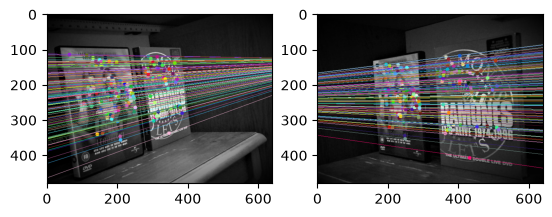

In [ ]:
# Find epilines corresponding to points
# in right image (second image) and
# drawing its lines on left image
linesLeft = cv2.computeCorrespondEpilines(
    ptsRight.reshape(-1, 1, 2),
    2,
    F
).reshape(-1, 3)

imgLeftEpi, _ = drawlines(
    imgLeft,
    imgRight,
    linesLeft,
    ptsLeft,
    ptsRight
)

# Find epilines corresponding to points in left image (first image) and
# drawing its lines on right image
linesRight = cv2.computeCorrespondEpilines(
    ptsLeft.reshape(-1, 1, 2),
    1,
    F
).reshape(-1, 3)

imgRightEpi, _ = drawlines(
    imgRight,
    imgLeft,
    linesRight,
    ptsRight,
    ptsLeft
)

plt.subplot(121), plt.imshow(img5)
plt.subplot(122), plt.imshow(img3)
plt.show()